# Непараметрические CUSUM-карты по знакам (SN) и знаковым рангам (SR)

**Контрольные карты кумулятивных сумм для медианы процесса в случае K
($\mu_0$ известно).** Знаковая карта не требует симметрии, знаково-ранговая —
требует; обе не зависят от вида непрерывного распределения.

Источник: Chakraborti, S. & Graham, M. A. (2019). *Nonparametric Statistical
Process Control*. Wiley — § 4.2.2 «CUSUM charts», стр. 202–208; рабочие
примеры § 4.3.2, стр. 229–243; дизайн $(k,h)$ — § 3.2.2, стр. 67–72.

> Ноутбук запускается из каталога `notebooks/` (kernel `python3`).

## 1. Импорты и настройка

Каталог `src` добавляется в `sys.path`; логика берётся из пакета
`nonparametric_charts`, в ячейках она не дублируется.

In [1]:
import sys
sys.path.append('../src')      # запуск из notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from nonparametric_charts.charts import CusumSignChart, CusumSignedRankChart
from nonparametric_charts.utils import (
    DataLoader, DataPreprocessor,
    cusum_sign_run_length, cusum_signed_rank_run_length,
)
from nonparametric_charts.utils.run_length_design import (
    design_sign_h, design_signed_rank_h, oc_curve,
)
from nonparametric_charts.utils.plot_style import (
    apply_minimal_latex_style, despine,
)

apply_minimal_latex_style()
print('Стиль графиков: минималистичный LaTeX')

Стиль графиков: минималистичный LaTeX


## 2. Теория

### 2.1. Постановка задачи *(§ 4.2.2, стр. 202)*

Независимые подгруппы $X_{i1},\ldots,X_{in}$, $i=1,2,\ldots$; целевое
значение $\mu_0$ известно (**Case K**). Вместо параметрического CUSUM по
$X_i-\mu_0$ (ур. 3.3–3.4, стр. 67) накапливается непараметрическая
статистика подгруппы $Z_i$:

$$S_i^{+}=\max\{0,\; S_{i-1}^{+}+Z_i-k\},\qquad
S_i^{-}=\min\{0,\; S_{i-1}^{-}+Z_i+k\}.$$

Сигнал — при $S_i^{+}\ge h$ (верхняя ветвь, сдвиг вверх) или
$S_i^{-}\le -h$ (нижняя). Параметры: $k>0$ — референсное значение,
$h>0$ — интервал решения.

### 2.2. Знаковая статистика (CUSUM-SN) *(ур. 4.5, стр. 190; ур. 4.7–4.8, стр. 203)*

$$SN_i=\sum_{j=1}^{n}\operatorname{sign}(X_{ij}-\mu_0)=2T_i-n,
\qquad T_i\sim\mathrm{Bin}(n,p).$$

В IC $p=P(X\ge\mu_0)=1/2$, поэтому $E(SN_i)=0$, $\mathrm{Var}(SN_i)=n$;
носитель — чётные числа $-n,\ldots,n$. Уравнение 4.11 печатного текста для
нижней ветви SR содержит опечатку: знак должен быть $+k$ (пример 4.9,
стр. 237), в реализации используется $+k$.

### 2.3. Знаково-ранговая статистика (CUSUM-SR) *(ур. 4.10–4.11, стр. 206)*

$$SR_i=\sum_{j=1}^{n}\operatorname{sign}(X_{ij}-\mu_0)\,R_{ij}
=2T_i^{+}-\frac{n(n+1)}{2},$$

где $R_{ij}$ — ранг $|X_{ij}-\mu_0|$ внутри подгруппы. В IC (при симметрии
$F$) $E(SR_i)=0$, $\mathrm{Var}(SR_i)=n(n+1)(2n+1)/6$ (табл. 4.3, стр. 200).

### 2.4. Длина серии *(§ 4.2.2.3, стр. 203–205; § 4.2.2.4.3, стр. 206)*

Для решётчатых $SN$/$SR$ распределение длины серии $RL$ считается точно
марковской цепью с матрицей переходов $Q$ непоглощающих состояний:

$$E(RL)=\xi^{\top}(I-Q)^{-1}\mathbf{1},\qquad
E(RL^2)=\xi^{\top}(I+Q)(I-Q)^{-2}\mathbf{1},$$

где $\xi$ — стартовое распределение (состояние $(0,0)$). $\mathrm{SDRL}=
\sqrt{E(RL^2)-E(RL)^2}$, $MRL$ — медиана. Подбор $h$: консервативно берётся
наибольшее $h$ с $ARL_{IC}\le$ номинала (§ 3.2.2, стр. 71).

## 3. Формулы в виде кода

Каждая формула выше имеет прямое выражение в пакете: статистики подгрупп —
`sign_statistic` / `signed_rank_statistic`, рекурсии — методы карт,
распределение RL — `*_run_length`.

In [2]:
from nonparametric_charts.utils.statistics import (
    sign_statistic, signed_rank_statistic,
)

row = np.array([-0.39, 0.03, 0.25, 0.30])
print('SN = 2T - n        :', sign_statistic(row, 0.0))
print('SR = 2T+ - n(n+1)/2:', signed_rank_statistic(row, 0.0))

# Рекурсия CUSUM-SN, ур. 4.7-4.8: один шаг для Z = SN
def cusum_step(z, s_plus, s_minus, k):
    return max(0.0, s_plus + z - k), min(0.0, s_minus + z + k)

print('шаг (Z=4, k=2, S+=1, S-=0):', cusum_step(4, 1, 0, 2))

SN = 2T - n        : 2
SR = 2T+ - n(n+1)/2: 2.0
шаг (Z=4, k=2, S+=1, S-=0): (3, 0.0)


## 4. Реализация: карта на своих данных

Демонстрационные данные — `../data/data.csv` (строка = подгруппа, столбец =
наблюдение). Целевое значение зададим явно ($\mu_0=0$), $k=1$, а $h$
подберём под номинальный $ARL_{IC}=500$ консервативным правилом.

In [3]:
loader = DataLoader('../data/data.csv')
raw = loader.load()
data, n = DataPreprocessor(raw).get_data_for_chart()
print('Размер данных:', data.shape, '| n =', n)
data.head()

Размер данных: (10, 14) | n = 14


,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,x11,x12,x13,x14
0,0.152,0.383,0.094,0.067,0.00001,0.316,0.3372,0.811,0.038,0.701,0.137,0.159,0.4571,0.2809
1,0.116,-1.647,0.098,0.642,0.79100,0.988,-0.1760,0.968,0.385,0.361,0.167,0.435,0.9870,0.9940
2,0.322,0.962,0.533,0.798,0.40100,0.838,0.1820,0.632,0.265,0.170,0.783,0.324,0.7710,0.0001
3,0.351,0.829,0.298,-1.892,0.95500,0.688,0.9880,0.477,0.301,0.291,0.565,0.995,0.8890,1.0290
4,0.279,0.003,0.168,22.437,0.87600,-0.127,-0.1370,0.240,0.190,0.289,0.335,0.764,0.2930,0.1120


In [4]:
# k выбираем по правилу книги (малое), h — под номинал 500
probe = design_sign_h(n, 500.0, 1.0, sided='two')
print(f'Подбор h: h={probe.h:g}, ARL_IC={probe.arl:.2f}, '
      f'отклонение={probe.relative_error:.1%}')

chart = CusumSignChart(data, sample_size=n, target_value=0.0,
                       k=1.0, h=probe.h)
limits = chart.calculate_limits()
for key in ('CL', 'UCL', 'LCL', 'k', 'h'):
    print(f'  {key:>3} = {limits[key]}')
print('Сигналы:', chart.violations or 'нет')

Подбор h: h=31, ARL_IC=490.32, отклонение=1.9%
   CL = 0.0
  UCL = 31.0
  LCL = -31.0
    k = 1.0
    h = 31.0
Сигналы: [{'subgroup': 3, 'side': 'upper', 'value': 35.0, 'counter': 3, 'rule': 'SN⁺ ≥ h = 31.0'}]


### 4.1. Разбор кода и логика

- `CusumSignChart` накапливает $SN_i^{+}$ и $SN_i^{-}$ по всем подгруппам;
  колонки `sn`, `sn_plus`, `sn_minus` — статистика и обе ветви,
  `nplus`/`nminus` — число подряд идущих ненулевых периодов (оценка точки
  сдвига $i-N$).
- `calculate_limits` не «рисует границы по sigma», а берёт заданные $k,h$:
  $UCL=+h$, $LCL=-h$, $CL=0$. Это соглашение CUSUM, а не карты Шухарта.
- Сигнал фиксируется один раз на сторону — первое пересечение; дальнейшие
  подгруппы на ту же сторону не дублируются.
- Если $h$ мало, ложные тревоги часты; номинал $ARL_{IC}$ и есть мера их
  частоты. Подбор $h$ — отдельная задача дизайна, а не свойство данных.

## 5. Графики

### 5.1. Карта и распределение длины серии

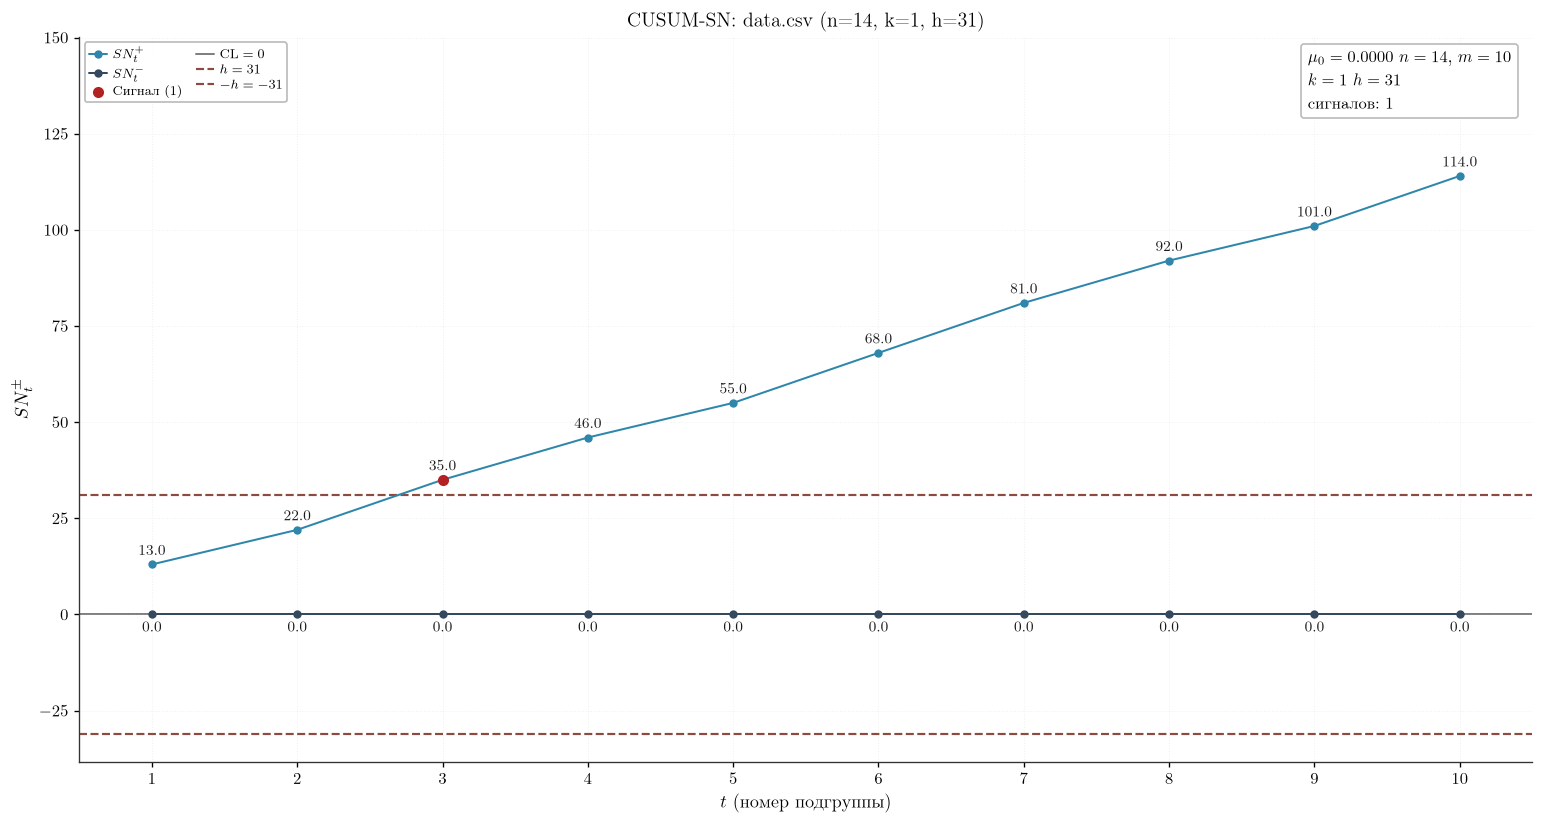

In [5]:
fig, ax = chart.plot(title=f'CUSUM-SN: data.csv (n={n}, k=1, h={probe.h:g})')
plt.show()

ARL  = 490.32
SDRL = 474.25
MRL  = 345
Перцентили: {'5%': 40, '25%': 153, '50%': 345, '75%': 674, '95%': 1437}


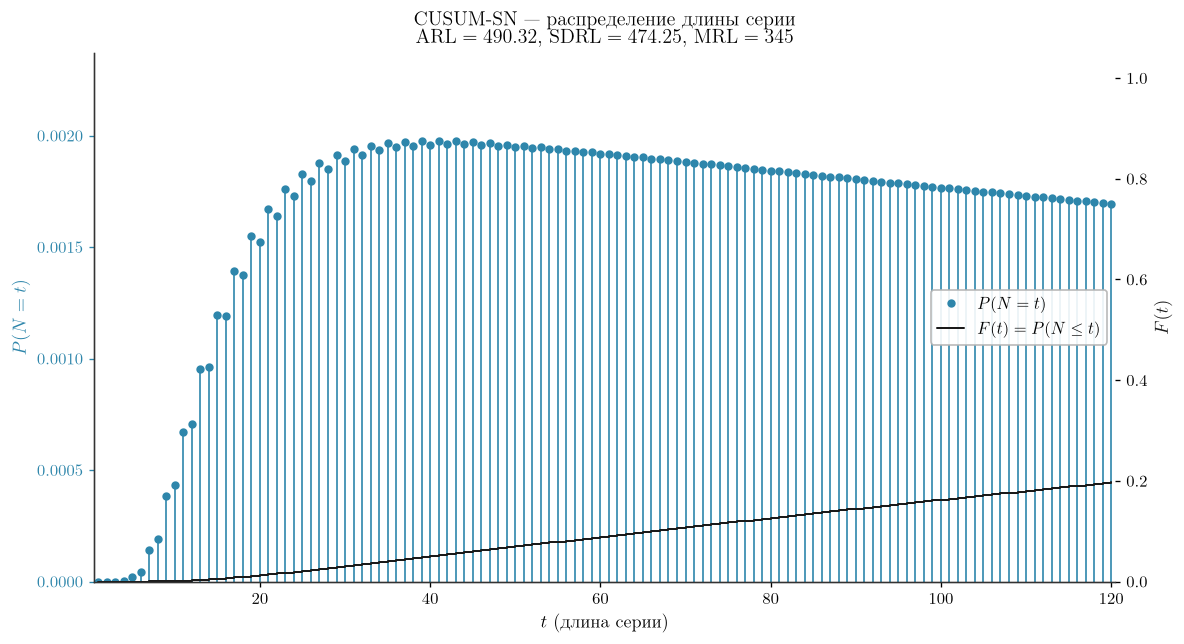

In [6]:
rl = chart.run_length(sided='two')
print('ARL  =', round(rl.arl, 2))
print('SDRL =', round(rl.sdrl, 2))
print('MRL  =', rl.mrl)
print('Перцентили:', {f'{q:.0%}': v for q, v in rl.percentiles.items()})

fig, ax = chart.plot_run_length(sided='two', max_t=120)
plt.show()

### 5.2. OC-кривая и ступенчатость $ARL(h)$

Слева — $\mathrm{ARL}(\delta)$ для дизайна рис. 4.5 ($n=10$, $k=6$, $h=4$):
в IC значение не зависит от распределения, в OOC — зависит. Справа —
$ARL_{IC}(h)$ при $k=6$: функция ступенчатая, поэтому номинал 500
недостижим точно.

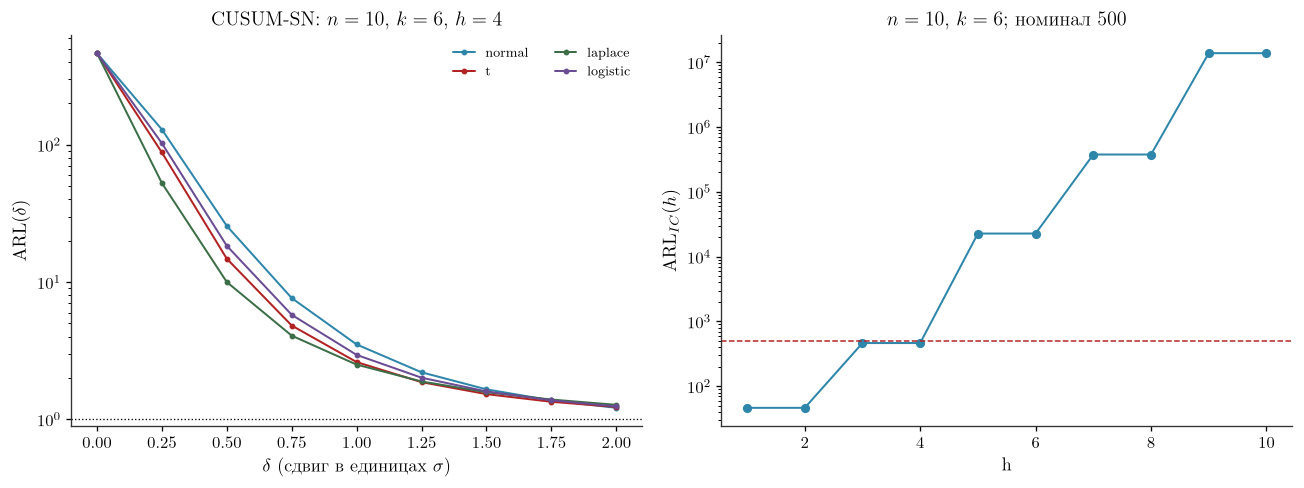

In [7]:
deltas = np.array([0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0])
curves = {
    name: oc_curve(10, 6, 4, deltas, statistic='SN', sided='two',
                   distribution=name)['arl'].to_numpy()
    for name in ('normal', 't', 'laplace', 'logistic')
}
h_grid = np.arange(1, 11, 1.0)
arl_h = np.array([
    cusum_sign_run_length(10, 6, h, sided='two').arl for h in h_grid
])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for name, values in curves.items():
    axes[0].plot(deltas, values, marker='o', markersize=2.5, label=name)
axes[0].set_yscale('log')
axes[0].set_xlabel(r'$\delta$ (сдвиг в единицах $\sigma$)')
axes[0].set_ylabel(r'$\mathrm{ARL}(\delta)$')
axes[0].set_title(r'CUSUM-SN: $n=10$, $k=6$, $h=4$')
axes[0].axhline(1.0, color='black', linewidth=0.8, linestyle=':')
axes[0].legend(frameon=False, fontsize=8, ncol=2)

axes[1].semilogy(h_grid, arl_h, marker='o')
axes[1].axhline(500, color='#B22222', linestyle='--', linewidth=0.9)
axes[1].set_xlabel('h')
axes[1].set_ylabel(r'$\mathrm{ARL}_{IC}(h)$')
axes[1].set_title(r'$n=10$, $k=6$; номинал 500')
for axis in axes:
    despine(axis)
fig.tight_layout()
plt.show()

## 6. Проверка по книге

### 6.1. Пример 4.7 (CUSUM-SN, табл. 4.6): сигнала нет

In [8]:
DATA_SN = [[-0.3, -1.28, 0.24, 1.28, 1.2, 1.73, -2.18, -0.23, 1.1, -1.09], [-0.69, -1.69, -1.85, -0.98, -0.77, -2.12, -0.57, -0.4, 0.13, -0.37], [-0.33, -0.37, 1.34, -0.09, -0.19, -0.51, 1.97, 0.87, 2.38, -0.65], [1.66, -1.61, 0.54, 0.9, 1.92, -0.08, -0.52, 0.68, -0.38, 0.76], [-1.44, -0.85, -1.52, -0.36, -0.03, 0.03, -0.32, 2.19, -1.74, -0.74], [-2.58, 1.45, -1.28, -0.65, 0.76, 0.47, 0.87, 0.6, -1.37, -1.12], [0.69, 0.32, -0.94, -0.24, 0.13, 0.56, 0.14, -0.91, 1.88, 0.49], [0.07, 0.83, 0.86, -0.64, -0.92, 1.11, -1.2, -1.56, 0.71, 0.64], [2.21, 1.44, 1.3, 0.11, 0.0, 0.45, -0.03, -1.05, -1.77, 0.83], [0.44, 0.62, 0.21, -1.03, 1.24, -0.31, -0.84, -0.82, -0.43, -0.45], [-0.52, 0.85, 0.51, -0.61, 1.3, -1.76, 0.55, -0.12, 0.04, -0.65], [-0.55, 0.85, 0.8, 0.46, 0.69, 1.63, 0.3, 0.59, 1.85, -0.34], [1.04, 0.14, 1.14, -0.15, -0.78, 1.08, -0.58, 0.53, 0.55, -0.32], [-0.44, -1.37, 1.99, -0.57, 0.09, -0.23, 2.84, 1.25, 0.88, 1.33], [0.19, 0.54, -0.25, -1.22, 1.27, -0.29, -1.31, 0.76, 0.78, 0.43]]   # табл. 4.6(a): 15 подгрупп по n = 10

sn_data = pd.DataFrame(DATA_SN)
sn_chart = CusumSignChart(sn_data, sample_size=10, target_value=0.0,
                          k=2.0, h=8.0)
sn_chart.calculate_limits()
print('Максимум S+ =', sn_chart.subgroups['sn_plus'].max())
print('Минимум  S- =', sn_chart.subgroups['sn_minus'].min())
print('Сигналы:', sn_chart.violations or 'нет')
assert not sn_chart.violations

Максимум S+ = 4.0
Минимум  S- = -6.0
Сигналы: нет


### 6.2. Пример 4.9 (CUSUM-SR, табл. 4.7a): сигналы $t=10$ и $t=12$

In [9]:
DATA_SR = [[-0.39, 0.03, 0.25, 0.3], [-0.61, -1.32, -2.84, -0.07], [2.04, 0.4, 0.54, 1.12], [-0.51, -1.63, 0.28, -0.96], [-0.2, -0.01, -0.21, 0.82], [2.03, 0.7, -1.21, -0.26], [0.64, 1.48, 0.91, 1.23], [0.19, -2.74, -0.85, 1.25], [-0.51, -1.77, -1.69, 0.24], [-0.84, -0.71, -0.82, 0.19], [0.29, 0.47, 0.04, 0.39], [0.38, 2.18, 1.24, -0.8], [-0.86, 0.61, -0.7, -1.13], [-0.31, 1.09, -0.43, 0.69], [0.42, 1.35, -0.51, -1.8], [0.39, -0.65, 1.57, -0.6], [1.31, -0.59, -0.21, 0.22], [0.64, 0.27, 0.26, 0.08], [-0.33, -0.49, 0.38, -1.54], [-0.48, -0.54, 1.73, -1.0]]   # табл. 4.7a(a): 20 подгрупп по n = 4

sr_data = pd.DataFrame(DATA_SR, columns=['x1', 'x2', 'x3', 'x4'])
sr_chart = CusumSignedRankChart(sr_data, sample_size=4, target_value=0.0,
                                k=3.0, h=8.0)
sr_chart.calculate_limits()
for violation in sr_chart.violations:
    print(f"t={violation['subgroup']:>2}  сторона={violation['side']:<5} "
          f"SR={violation['value']:>3g}  N={violation['counter']}")
print('SR по подгруппам:', sr_chart.subgroups['sr'].tolist())

t=10  сторона=lower SR=-10  N=2
t=12  сторона=upper SR= 10  N=2
SR по подгруппам: [2.0, -10.0, 10.0, -8.0, -2.0, 2.0, 10.0, -2.0, -8.0, -8.0, 10.0, 6.0, -8.0, 4.0, -2.0, 0.0, 2.0, 10.0, -6.0, -2.0]


### 6.3. Примеры 4.8 и 4.10: марковское $ARL$

In [10]:
ex_4_8 = cusum_sign_run_length(5, 1, 4, sided='upper')
ex_4_10 = cusum_signed_rank_run_length(4, 2, 6, sided='upper')
print(f'4.8  ARL={ex_4_8.arl:.3f}  SDRL={ex_4_8.sdrl:.3f}  MRL={ex_4_8.mrl}')
print(f'4.10 ARL={ex_4_10.arl:.3f}  SDRL={ex_4_10.sdrl:.3f}  MRL={ex_4_10.mrl}')
print('Книга: 16.62 / 6.81')

4.8  ARL=16.615  SDRL=15.509  MRL=12
4.10 ARL=6.809  SDRL=6.106  MRL=5
Книга: 16.62 / 6.81


### 6.4. Рис. 4.5 и 4.6: дизайн и открытое расхождение

Рис. 4.5 книги (стр. 204) — SAS-вывод RL для $n=10$, $k=6$, $h=4$:
книжное среднее $454.24$, точный расчёт даёт $464.98$ (ошибка 2.4 %).
Рис. 4.6 (стр. 207) для $n=10$, $k=41$, $h=24$ заявляет $500.30$;
точный двусторонний расчёт даёт $\approx 80\,600$, а подбор под 500 —
$h=14$ и $ARL\approx 487$. Код не подгоняется под печатное значение.

In [11]:
fig_4_5 = design_sign_h(10, 500.0, 6.0, sided='two')
fig_4_6_design = design_signed_rank_h(10, 500.0, 41.0, sided='two')
book_h24 = cusum_signed_rank_run_length(10, 41, 24, sided='two',
                                       max_quantile=0.5)
print(f'Рис. 4.5: h={fig_4_5.h:g}, ARL_IC={fig_4_5.arl:.2f} '
      f'(книга 454.24)')
print(f'Рис. 4.6: подбор h={fig_4_6_design.h:g}, '
      f'ARL_IC={fig_4_6_design.arl:.2f}')
print(f'          при книжном h=24: ARL={book_h24.arl:,.0f} '
      f'(книга 500.30)')

Рис. 4.5: h=4, ARL_IC=464.98 (книга 454.24)
Рис. 4.6: подбор h=14, ARL_IC=486.87
          при книжном h=24: ARL=80,613 (книга 500.30)


## 7. Итог

| Величина | Формула | Источник |
| --- | --- | --- |
| Статистика знаков | $SN_i=2T_i-n$ | ур. 4.5, стр. 190 |
| Статистика знаковых рангов | $SR_i=2T_i^{+}-n(n+1)/2$ | ур. 4.5, стр. 197 |
| Верхняя/нижняя ветви | $S_i^{+}=\max(0,S_{i-1}^{+}+Z_i-k)$, $S_i^{-}=\min(0,S_{i-1}^{-}+Z_i+k)$ | ур. 4.7–4.8, 4.10–4.11, стр. 203, 206 |
| Правило сигнала | $S_i^{+}\ge h$ или $S_i^{-}\le -h$ | стр. 203, 206 |
| Средняя длина серии | $E(RL)=\xi^{\top}(I-Q)^{-1}\mathbf{1}$ | ур. 3.22–3.24, стр. 112 |
| Дизайн $h$ | наибольшее $h$ с $ARL_{IC}\le$ номинала | § 3.2.2, стр. 71 |

**Что проверено:** примеры 4.7 (сигнала нет), 4.9 (сигналы $t=10$ и $t=12$),
4.8 и 4.10 ($ARL=16.62$ и $6.809$); дизайн по рис. 4.5 ($h=4$,
$ARL=464.98$). **Открытый вопрос:** рис. 4.6 ($n=10$, $k=41$, $h=24$) не
воспроизводит книжные $500.30$ — точный расчёт даёт $\approx 80\,600$;
расхождение подтверждено независимой имитацией и R-пакетом `npSPC`
(см. `docs/reports/cusum_verification.tex`). Для практики рекомендуется
консервативный подбор $h$ и вычисленные дизайны, а не печатное значение.